In [1]:
!nvidia-smi

Wed Mar 19 16:49:35 2025       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 560.94                 Driver Version: 560.94         CUDA Version: 12.6     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                  Driver-Model | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 3060      WDDM  |   00000000:26:00.0  On |                  N/A |
|  0%   44C    P8             12W /  170W |     676MiB /  12288MiB |      2%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

Using device: cuda
Dataset loaded successfully with 8991 samples
Found 8 classes: ['1', '2', '3', '4', '5', '6', '7', '8']
Dataset split: 6293 training, 899 validation, 1799 test samples
Enhanced model initialized with 8 output classes
Starting training for 100 epochs...


Validation: 100%|██████████████████████████████████████████████████████████████████████| 57/57 [00:15<00:00,  3.58it/s]


Epoch 1/100 | Train Loss: 1.7204, Train Acc: 0.3401 | Val Loss: 1.2223, Val Acc: 0.5495
Enhanced model saved with val acc: 0.5495


Validation: 100%|██████████████████████████████████████████████████████████████████████| 57/57 [00:11<00:00,  4.86it/s]


Epoch 2/100 | Train Loss: 1.0681, Train Acc: 0.6147 | Val Loss: 0.9708, Val Acc: 0.6541
Enhanced model saved with val acc: 0.6541


Validation: 100%|██████████████████████████████████████████████████████████████████████| 57/57 [00:11<00:00,  4.93it/s]


... (191 outputs left out)

Validation: 100%|██████████████████████████████████████████████████████████████████████| 57/57 [00:11<00:00,  5.09it/s]


Epoch 99/100 | Train Loss: 0.0012, Train Acc: 0.9995 | Val Loss: 0.4618, Val Acc: 0.9344


Validation: 100%|██████████████████████████████████████████████████████████████████████| 57/57 [00:10<00:00,  5.18it/s]


Epoch 100/100 | Train Loss: 0.0007, Train Acc: 0.9997 | Val Loss: 0.4690, Val Acc: 0.9355
Training completed. Best validation accuracy: 0.9366


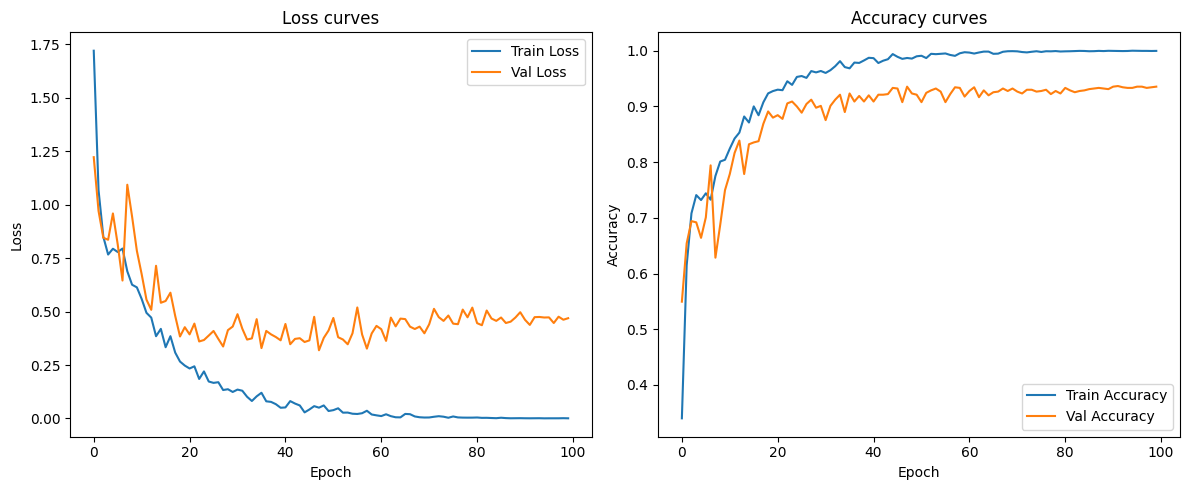

Evaluating enhanced model on test set...


Validation: 100%|████████████████████████████████████████████████████████████████████| 113/113 [00:32<00:00,  3.48it/s]

Test Loss: 0.4808, Test Accuracy: 0.9355


In [ ]:
import sys
from pathlib import Path

# make the repository modules available when the notebook runs from notebooks/.
REPOSITORY_ROOT = Path.cwd().parent
if str(REPOSITORY_ROOT) not in sys.path:
    sys.path.insert(0, str(REPOSITORY_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms as transforms
from PIL import Image
from sklearn.metrics import accuracy_score
from torch.utils.data import DataLoader, Dataset, random_split
from tqdm import tqdm

from models import EnhancedMultimodalModel
from src.data_loader import CoordinateImageDataset
from src.train import train_epoch, validate

# keep the notebook's original class name available for existing cells.
EnhancedMultimodalModel = EnhancedMultimodalModel


In [ ]:
# Load the best model and evaluate with comprehensive metrics
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, 
    confusion_matrix, roc_curve, auc, cohen_kappa_score,
    matthews_corrcoef, mean_squared_error, mean_absolute_error
)
from sklearn.preprocessing import label_binarize
from itertools import cycle

def evaluate_model(model, test_loader, device, class_names):
    model.eval()
    all_preds = []
    all_labels = []
    all_probs = []
    
    with torch.no_grad():
        for images, coords, labels in test_loader:
            images, coords, labels = images.to(device), coords.to(device), labels.to(device)
            outputs = model(images, coords)
            probs = torch.nn.functional.softmax(outputs, dim=1)
            _, preds = torch.max(outputs, 1)
            
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())
    
    y_true = np.array(all_labels)
    y_pred = np.array(all_preds)
    y_probs = np.array(all_probs)
    
    # Basic metrics
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, average='weighted')
    recall = recall_score(y_true, y_pred, average='weighted')
    f1 = f1_score(y_true, y_pred, average='weighted')
    kappa = cohen_kappa_score(y_true, y_pred)
    mcc = matthews_corrcoef(y_true, y_pred)
    
    # Generate confusion matrix
    cm = confusion_matrix(y_true, y_pred)
    
    # Calculate class-wise metrics
    num_classes = len(class_names)
    class_metrics = []
    
    for i in range(num_classes):
        # Binary classification metrics for each class
        true_bin = (y_true == i).astype(int)
        pred_bin = (y_pred == i).astype(int)
        
        TP = np.sum((true_bin == 1) & (pred_bin == 1))
        TN = np.sum((true_bin == 0) & (pred_bin == 0))
        FP = np.sum((true_bin == 0) & (pred_bin == 1))
        FN = np.sum((true_bin == 1) & (pred_bin == 0))
        
        # Calculate metrics
        specificity = TN / (TN + FP) if (TN + FP) > 0 else 0
        npv = TN / (TN + FN) if (TN + FN) > 0 else 0
        fpr = FP / (FP + TN) if (FP + TN) > 0 else 0
        fdr = FP / (FP + TP) if (FP + TP) > 0 else 0
        fnr = FN / (FN + TP) if (FN + TP) > 0 else 0
        
        class_metrics.append({
            'class': class_names[i],
            'specificity': specificity,
            'npv': npv,
            'fpr': fpr,
            'fdr': fdr,
            'fnr': fnr
        })
    
    # Calculate RMSE and MAE
    y_true_bin = label_binarize(y_true, classes=range(num_classes))
    rmse = np.sqrt(mean_squared_error(y_true_bin, y_probs))
    mae = mean_absolute_error(y_true_bin, y_probs)
    
    # Return all metrics and data for plotting
    return {
        'accuracy': accuracy,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'kappa': kappa,
        'mcc': mcc,
        'rmse': rmse,
        'mae': mae,
        'confusion_matrix': cm,
        'class_metrics': class_metrics,
        'y_true': y_true,
        'y_pred': y_pred,
        'y_probs': y_probs
    }

def plot_all_metrics(results, class_names):
    num_classes = len(class_names)
    
    # 1. Plot confusion matrix
    plt.figure(figsize=(10, 8), dpi=500)
    sns.heatmap(results['confusion_matrix'], annot=True, fmt='d', cmap='Blues', 
                xticklabels=class_names, yticklabels=class_names)
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.title('Confusion Matrix')
    plt.tight_layout()
    plt.savefig('confusion_matrix.png', dpi=500, bbox_inches='tight')
    plt.close()
    
    # 2. Plot ROC curves
    y_true_bin = label_binarize(results['y_true'], classes=range(num_classes))
    y_probs = results['y_probs']
    
    plt.figure(figsize=(10, 8), dpi=500)
    colors = cycle(['aqua', 'darkorange', 'cornflowerblue', 'green', 'red', 'purple', 'brown', 'pink'])
    
    # Plot ROC curve for each class
    for i, color in zip(range(num_classes), colors):
        fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_probs[:, i])
        roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, color=color, lw=2,
                 label=f'ROC curve of class {class_names[i]} (AUC = {roc_auc:.2f})')
    
    # Plot diagonal line
    plt.plot([0, 1], [0, 1], 'k--', lw=2)
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('ROC Curves')
    plt.legend(loc="lower right")
    plt.savefig('roc_curves.png', dpi=500, bbox_inches='tight')
    plt.close()
    
    # 3. Plot Accuracy Bar Chart
    plt.figure(figsize=(10, 6), dpi=500)
    metrics = ['accuracy', 'precision', 'recall', 'f1', 'kappa', 'mcc']
    values = [results[m] for m in metrics]
    
    plt.bar(metrics, values, color='skyblue')
    plt.ylim(0, 1)
    plt.ylabel('Score')
    plt.title('Model Performance Metrics')
    
    # Add value labels on top of each bar
    for i, v in enumerate(values):
        plt.text(i, v + 0.02, f'{v:.3f}', ha='center')
    
    plt.tight_layout()
    plt.savefig('accuracy_metrics.png', dpi=500, bbox_inches='tight')
    plt.close()

# Main evaluation function
def main():
    # Set device
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Using device: {device}")
    
    # Load the dataset
    data_root = "ImageDataset"  # Update with your path
    csv_file = "image_coordinates.csv"  # Update with your path
    
    # Data transformations
    transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ])
    
    # Create dataset
    dataset = CoordinateImageDataset(data_root, csv_file, transform=transform)
    class_names = dataset.classes
    num_classes = len(class_names)
    print(f"Found {num_classes} classes: {class_names}")
    
    # Split dataset using the same seed as in training
    dataset_size = len(dataset)
    train_size = int(0.7 * dataset_size)
    val_size = int(0.1 * dataset_size)
    test_size = dataset_size - train_size - val_size
    
    torch.manual_seed(42)
    train_dataset, val_dataset, test_dataset = random_split(
        dataset, [train_size, val_size, test_size],
        generator=torch.Generator().manual_seed(42)
    )
    
    # Create data loader for test set
    test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False, num_workers=0)
    
    # Initialize model
    model = EnhancedMultimodalModel(
        num_classes=num_classes, 
        coord_dim=66, 
        transformer_layers=2
    ).to(device)
    
    # Load best model weights
    model.load_state_dict(torch.load("best_enhanced_multimodal_model.pth", map_location=device))
    print("Model weights loaded successfully")
    
    # Evaluate the model
    print("Evaluating model on test set...")
    results = evaluate_model(model, test_loader, device, class_names)
    
    # Print metrics
    print("\n========== Model Evaluation Results ==========")
    print(f"Accuracy: {results['accuracy']:.4f}")
    print(f"Precision: {results['precision']:.4f}")
    print(f"Recall: {results['recall']:.4f}")
    print(f"F1 Score: {results['f1']:.4f}")
    print(f"Cohen's Kappa: {results['kappa']:.4f}")
    print(f"Matthews Correlation Coefficient: {results['mcc']:.4f}")
    print(f"RMSE: {results['rmse']:.4f}")
    print(f"MAE: {results['mae']:.4f}")
    
    # Print class-wise metrics
    print("\nClass-wise Metrics:")
    print("Class\tSpecificity\tNPV\t\tFPR\t\tFDR\t\tFNR")
    for m in results['class_metrics']:
        print(f"{m['class']}\t{m['specificity']:.4f}\t\t{m['npv']:.4f}\t\t{m['fpr']:.4f}\t\t{m['fdr']:.4f}\t\t{m['fnr']:.4f}")
    
    # Generate and save all plots
    print("\nGenerating plots...")
    plot_all_metrics(results, class_names)
    print("All plots saved with 500 DPI")

if __name__ == "__main__":
    main()


# sensitivity = recall.
# f1_score = 2 * (precision * recall) / (precision + recall)

Using device: cuda
Found 8 classes: ['1', '2', '3', '4', '5', '6', '7', '8']
Model weights loaded successfully
Evaluating model on test set...

========== Model Evaluation Results ==========
Accuracy: 0.9389
Precision: 0.9386
Recall: 0.9389
F1 Score: 0.9385
Cohen's Kappa: 0.9300
Matthews Correlation Coefficient: 0.9300
RMSE: 0.1205
MAE: 0.0156

Class-wise Metrics:
Class	Specificity	NPV		FPR		FDR		FNR
1	0.9943		0.9975		0.0057		0.0415		0.0189
2	0.9806		0.9838		0.0194		0.1154		0.0980
3	0.9865		0.9872		0.0135		0.0875		0.0837
4	0.9831		0.9736		0.0169		0.1053		0.1565
5	0.9930		0.9968		0.0070		0.0451		0.0210
6	0.9943		0.9924		0.0057		0.0393		0.0517
7	0.9988		0.9988		0.0012		0.0121		0.0121
8	0.9988		0.9994		0.0012		0.0102		0.0051

Generating plots...
All plots saved with 500 DPI
